# Cell 1: Environment & Data Setup

In [1]:
!pip install ultralytics -q
import sys

# THE FIX: Wipe Kaggle's internal background arguments so Ultralytics doesn't crash
if hasattr(sys, 'argv'):
    sys.argv = ['']

import yaml
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Find your dataset
INPUT_DATASET_PATH = "/kaggle/input/tfp-dataset-fixed/tfp_dataset" 

yaml_data = {
    'train': f'{INPUT_DATASET_PATH}/train/images',
    'val': f'{INPUT_DATASET_PATH}/val/images',
    'test': f'{INPUT_DATASET_PATH}/test/images',
    'nc': 9,
    'names': ["Car", "Bus", "Truck", "Motorcycle", "Bicycle", "Rickshaw", "Mini-Truck", "CNG", "Pedestrian"]
}

with open('/kaggle/working/data.yaml', 'w') as f:
    yaml.dump(yaml_data, f)
    
print("Environment ready and data.yaml generated for 9 classes!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.4/61.4 kB 4.0 MB/s eta 0:00:00
Environment ready and data.yaml generated for 9 classes!


# Cell 2: Train YOLOv8 (Advanced)

In [2]:
!pip install ultralytics -q
import os
import sys
import yaml
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Wipe Kaggle's internal background arguments so Ultralytics doesn't crash
if hasattr(sys, 'argv'):
    sys.argv = ['']

print("Hunting for the mounted dataset in Kaggle inputs...")
INPUT_DATASET_PATH = None

# Dynamically dig through Kaggle's input folders to find your dataset
for root, dirs, files in os.walk('/kaggle/input'):
    if 'tfp_dataset' in dirs:
        INPUT_DATASET_PATH = os.path.join(root, 'tfp_dataset')
        break 

# Failsafe check
if INPUT_DATASET_PATH is None:
    raise FileNotFoundError(
        "CRITICAL ERROR: Could not find 'tfp_dataset'.\n"
        "1. Did Notebook A successfully finish committing?\n"
        "2. Did you click 'Add Input' in this notebook to mount Notebook A's output?"
    )

print(f"Success! Found dataset perfectly at: {INPUT_DATASET_PATH}")

# Dynamically generate the YAML file with the exact correct path
yaml_data = {
    'train': f'{INPUT_DATASET_PATH}/train/images',
    'val': f'{INPUT_DATASET_PATH}/val/images',
    'test': f'{INPUT_DATASET_PATH}/test/images',
    'nc': 9,
    'names': ["Car", "Bus", "Truck", "Motorcycle", "Bicycle", "Rickshaw", "Mini-Truck", "CNG", "Pedestrian"]
}

with open('/kaggle/working/data.yaml', 'w') as f:
    yaml.dump(yaml_data, f)
    
print("Environment ready and data.yaml generated securely for all 9 classes!")

Hunting for the mounted dataset in Kaggle inputs...
Success! Found dataset perfectly at: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset
Environment ready and data.yaml generated securely for all 9 classes!


# Cell 3: Train YOLOv11 (Advanced)

In [3]:
from ultralytics import YOLO

# 2. Load YOLOv11 Nano
model_v11 = YOLO('yolo11n.pt') 

print("Starting YOLOv11 Advanced Training...")
results_v11 = model_v11.train(
    data='/kaggle/working/data.yaml',
    epochs=30,          
    imgsz=640,        
    batch=16,           
    project='/kaggle/working/runs', 
    name='yolov11_advanced',
    
    # Advanced Augmentations (Kept identical for fair thesis comparison)
    mosaic=1.0,          
    mixup=0.2,           
    copy_paste=0.1       
)

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Starting YOLOv11 Advanced Training...
Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_o

# Cell 4: Generate Publication Visuals for the Thesis

--- THESIS VISUALS FOR YOLOV11_ADVANCED ---

Confusion Matrix:


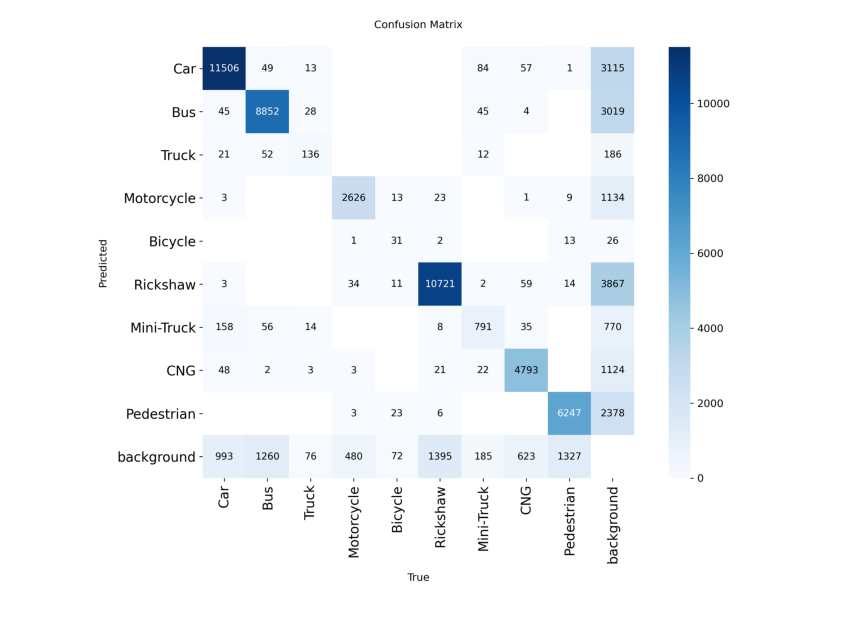


Training Results:


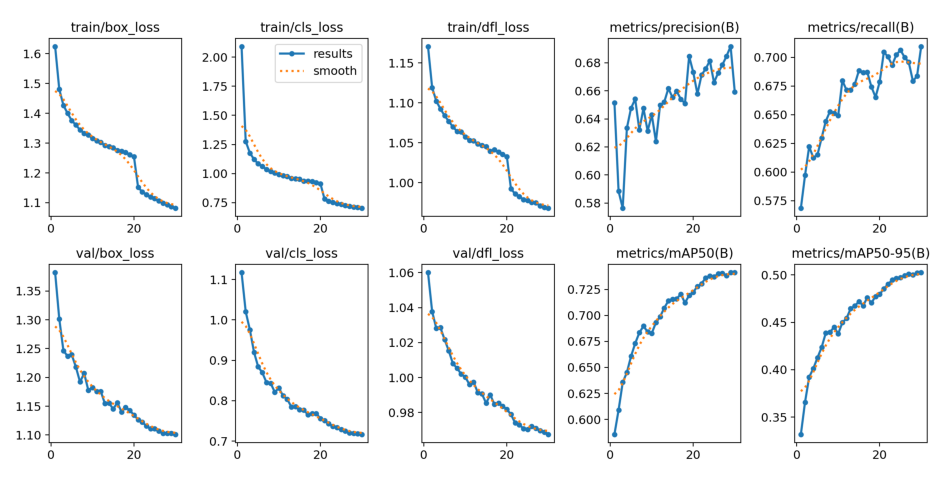

In [4]:
def display_thesis_visuals(model_name):
    base_path = f'/kaggle/working/runs/{model_name}'
    
    # The 4 most critical plots for a computer vision research paper
    visuals = [
        ('Confusion Matrix', 'confusion_matrix.png'),
        ('Precision-Recall Curve', 'PR_curve.png'),
        ('F1-Confidence Curve', 'F1_curve.png'),
        ('Training Results', 'results.png')
    ]
    
    print(f"--- THESIS VISUALS FOR {model_name.upper()} ---")
    
    for title, filename in visuals:
        img_path = os.path.join(base_path, filename)
        if os.path.exists(img_path):
            print(f"\n{title}:")
            img = mpimg.imread(img_path)
            plt.figure(figsize=(12, 8))
            plt.imshow(img)
            plt.axis('off')
            plt.show()
        else:
            print(f"Warning: {filename} not found.")

# Display visuals for YOLOv11 (Change to 'yolov8_advanced' to see v8)
display_thesis_visuals('yolov11_advanced')